# Proyecto: seguimiento de satélites

La idea: tomar el catálogo de **todos los satélites activos**, contarlos, ver cómo creció su cantidad y calcular **dónde está cada uno** en un instante dado.

- Los datos: CelesTrak (https://celestrak.org/NORAD/elements/)
- Los cálculos astronómicos: la librería Skyfield
- El código va en módulos `.py`; el informe, en un notebook que los importa

In [1]:
import sys
sys.path.append('../proyesat')   # para importar funciones_base.py

import json
from datetime import datetime, timedelta, timezone
import numpy as np
import matplotlib.pyplot as plt

## Los datos: un JSON con una lista de diccionarios

In [2]:
with open('../proyesat/datos/satelites.json', encoding='utf-8') as f:
    registros = json.load(f)
type(registros), len(registros)

(list, 16710)

In [3]:
registros[0]

{'OBJECT_NAME': 'CALSPHERE 1',
 'OBJECT_ID': '1964-063C',
 'EPOCH': '2026-10-14T14:21:25.466688',
 'MEAN_MOTION': 13.76730837,
 'ECCENTRICITY': 0.00243553,
 'INCLINATION': 90.2208,
 'RA_OF_ASC_NODE': 74.5342,
 'ARG_OF_PERICENTER': 291.4443,
 'MEAN_ANOMALY': 198.023,
 'EPHEMERIS_TYPE': 0,
 'CLASSIFICATION_TYPE': 'U',
 'NORAD_CAT_ID': 900,
 'ELEMENT_SET_NO': 999,
 'REV_AT_EPOCH': 8785,
 'BSTAR': 0.00056429819,
 'MEAN_MOTION_DOT': 5.64e-06,
 'MEAN_MOTION_DDOT': 0}

In [4]:
# los nombres de los primeros
[r['OBJECT_NAME'] for r in registros[:10]]

['CALSPHERE 1',
 'CALSPHERE 2',
 'LCS 1',
 'TEMPSAT 1',
 'CALSPHERE 4A',
 'OPS 5712 (P/L 160)',
 'LES-5',
 'SURCAL 159',
 'OPS 5712 (P/L 153)',
 'RIGIDSPHERE 2 (LCS 4)']

In [5]:
# buscamos la Estación Espacial Internacional
iss = [r for r in registros if r['OBJECT_NAME'] == 'ISS (ZARYA)'][0]
iss

{'OBJECT_NAME': 'ISS (ZARYA)',
 'OBJECT_ID': '1998-067A',
 'EPOCH': '2026-10-14T08:06:39.057984',
 'MEAN_MOTION': 15.48861773,
 'ECCENTRICITY': 0.00067245,
 'INCLINATION': 51.6325,
 'RA_OF_ASC_NODE': 70.4557,
 'ARG_OF_PERICENTER': 261.592,
 'MEAN_ANOMALY': 98.4307,
 'EPHEMERIS_TYPE': 0,
 'CLASSIFICATION_TYPE': 'U',
 'NORAD_CAT_ID': 25544,
 'ELEMENT_SET_NO': 999,
 'REV_AT_EPOCH': 59022,
 'BSTAR': 0.00011949953,
 'MEAN_MOTION_DOT': 6.109e-05,
 'MEAN_MOTION_DDOT': 0}

Sólo vamos a usar directamente dos claves:

- `OBJECT_NAME`: el nombre
- `OBJECT_ID`: el identificador internacional, empieza con el **año de lanzamiento**

In [6]:
iss['OBJECT_NAME'], iss['OBJECT_ID']

('ISS (ZARYA)', '1998-067A')

In [7]:
# ¿cuántos Starlink hay?
len([r for r in registros if r['OBJECT_NAME'].startswith('STARLINK')])

11125

El resto de las claves describen la órbita (formato OMM). No hace falta entenderlas: el diccionario entero se le pasa a Skyfield.

## La fecha de los datos: `EPOCH`

Cada satélite trae la fecha en que se midió su órbita.

In [8]:
iss['EPOCH']

'2026-10-14T08:06:39.057984'

In [9]:
from funciones_base import epoch_medio

fecha_datos = epoch_medio(registros)
fecha_datos

datetime.datetime(2026, 10, 14, 6, 30, 18, 482258, tzinfo=datetime.timezone.utc)

In [10]:
ahora = datetime.now(timezone.utc)
ahora - fecha_datos

datetime.timedelta(days=6, seconds=23903, microseconds=749712)

## ¿Dónde está la ISS ahora?

In [11]:
from funciones_base import crear_objeto_skyfield, obtener_posicion, obtener_trayectoria

sat_iss = crear_objeto_skyfield(iss)
sat_iss

<EarthSatellite ISS (ZARYA) catalog #25544 epoch 2026-10-14 08:06:39 UTC>

In [12]:
lat, lon, alt = obtener_posicion(sat_iss, ahora)
lat, lon, alt

(51.7732, -98.3228, 430.259)

Comparen con https://satellitemap.space/ o con cualquier sitio que muestre la ISS en vivo.

## Un día entero de la ISS

`obtener_trayectoria` calcula muchas posiciones de una vez y devuelve arrays de numpy.

In [13]:
lats, lons, alts = obtener_trayectoria(sat_iss, ahora, 24, 1)   # 24 horas, cada 1 minuto
lats.shape

(1440,)

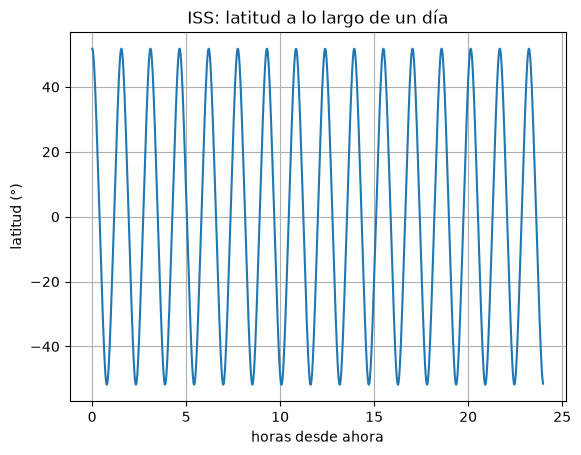

In [14]:
horas = np.arange(len(lats)) / 60
plt.plot(horas, lats)
plt.xlabel('horas desde ahora')
plt.ylabel('latitud (°)')
plt.title('ISS: latitud a lo largo de un día')
plt.grid()

- ¿Por qué la latitud nunca pasa de ±51.6°? (miren la clave `INCLINATION`)
- ¿Cuántas vueltas a la Tierra da por día? (miren `MEAN_MOTION`)
- En el proyecto van a graficar la **altitud**: ¿será constante?

In [15]:
iss['INCLINATION'], iss['MEAN_MOTION']

(51.6325, 15.48861773)

## ¿Y si pedimos la posición muy lejos de `EPOCH`?

La órbita real cambia: el roce con la atmósfera frena a los satélites bajos y cada tanto se encienden motores (la ISS recibe *reboosts*: https://heavens-above.com/OrbitHeight.aspx?satid=25544). Los datos no saben nada de eso.

In [16]:
# calculamos la altitud de todos los satélites a 0, 30 y 365 días de la fecha de los datos
objetos = [crear_objeto_skyfield(r) for r in registros]

for dias in [0, 30, 365]:
    momento = fecha_datos + timedelta(days=dias)
    alts = np.array([obtener_posicion(o, momento)[2] for o in objetos])
    print(f'{dias:3} días: {np.sum(alts < 0):3} satélites bajo tierra, {np.sum(np.isnan(alts)):3} sin resultado (nan)')

  0 días:   0 satélites bajo tierra,   0 sin resultado (nan)


 30 días:  69 satélites bajo tierra,  23 sin resultado (nan)


365 días: 426 satélites bajo tierra, 463 sin resultado (nan)


Ninguno de esos satélites está realmente bajo tierra: son satélites bajos cuya órbita, calculada tan lejos de `EPOCH`, ya no tiene sentido.

Por eso **el momento del cálculo no puede estar lejos de la fecha de los datos**. El archivo lo vamos a ir renovando.

## Lo que tienen que hacer

Módulos (cada función con *docstring*):

| Módulo | Qué hace |
|---|---|
| `catalogo.py` | leer el JSON, agrupar (Starlink, OneWeb, GPS, ...), contar lanzamientos por año |
| `satelite.py` | la clase `Satelite` (nombre, lat, lon, altitud, tipo de órbita) |
| `analisis.py` | conteos, extremos, ordenar, satélites en una zona |

Y el `informe.ipynb`, que **sólo importa y llama** funciones de los módulos, con texto que explique lo que se ve.

Una **zona** es un rectángulo `(lon_min, lat_min, lon_max, lat_max)`; para armarlas: https://bboxfinder.com

Se entrega en dos etapas: la **Etapa 1** es todo esto: una foto de los satélites en un instante, y se entrega el **viernes 30/10**. Los satélites a lo largo del tiempo (pases de la ISS, Bariloche durante un día) y los gráficos son la **Etapa 2**, en noviembre.

- En grupos de dos, repositorio con commits de los dos.
- Instalación de skyfield: `instalacion.md`.
- Todo el detalle: `README.md` del proyecto.